# Variational Autoencoder (VAE)

Useful links:
* Original paper http://arxiv.org/abs/1312.6114
* Helpful videos explaining the topic
   * https://www.youtube.com/watch?v=P78QYjWh5sM     
   * http://videolectures.net/deeplearning2015_courville_autoencoder_extension/?q=aaron%20courville

### Download data

In [ ]:
!pip install wandb -q

import wandb
wandb.login()

wandb: Using wandb-core as the SDK backend.  Please refer to https://wandb.me/wandb-core for more information.


<IPython.core.display.Javascript object>

wandb: Logging into wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: You can find your API key in your browser here: https://wandb.ai/authorize
wandb: Paste an API key from your profile and hit enter, or press ctrl+c to quit:

 ··········


wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc


True

In [ ]:
!pip install gdown

In [ ]:
import gdown
gdown.download('https://drive.google.com/file/d/1XyZrkefGaInjKqnc6f7jx2TSs8NxiIvM/view?usp=share_link', output='celeba.zip', fuzzy=True)

Downloading...
From (original): https://drive.google.com/uc?id=1XyZrkefGaInjKqnc6f7jx2TSs8NxiIvM
From (redirected): https://drive.google.com/uc?id=1XyZrkefGaInjKqnc6f7jx2TSs8NxiIvM&confirm=t&uuid=69b6995c-f686-4f45-b35b-ff93220882b8
To: /content/celeba.zip
100%|██████████| 1.43G/1.43G [00:17<00:00, 81.8MB/s]


'celeba.zip'

Or you can download it manually from Yandex Disk https://disk.yandex.ru/d/QErNx-MoC-2Y6Q

In [ ]:
!unzip celeba.zip

Выходные данные были обрезаны до нескольких последних строк (5000).
  inflating: celeba/celeba/img_align_celeba/138950.jpg  
  inflating: celeba/celeba/img_align_celeba/117264.jpg  
  inflating: celeba/celeba/img_align_celeba/112606.jpg  
  inflating: celeba/celeba/img_align_celeba/053676.jpg  
  inflating: celeba/celeba/img_align_celeba/158869.jpg  
  inflating: celeba/celeba/img_align_celeba/170252.jpg  
  inflating: celeba/celeba/img_align_celeba/021665.jpg  
  inflating: celeba/celeba/img_align_celeba/174525.jpg  
  inflating: celeba/celeba/img_align_celeba/042747.jpg  
  inflating: celeba/celeba/img_align_celeba/165952.jpg  
  inflating: celeba/celeba/img_align_celeba/148026.jpg  
  inflating: celeba/celeba/img_align_celeba/015537.jpg  
  inflating: celeba/celeba/img_align_celeba/107859.jpg  
  inflating: celeba/celeba/img_align_celeba/127972.jpg  
  inflating: celeba/celeba/img_align_celeba/056173.jpg  
  inflating: celeba/celeba/img_align_celeba/065547.jpg  
  inflating: celeba/

## Prepare the data

In [ ]:
import numpy as np
from matplotlib import pyplot as plt
from IPython import display

import torch
from torch import nn
from torch import optim
from torch.utils.data import Dataset, DataLoader

import torchvision
from torchvision.utils import make_grid

device = torch.device("cuda")

In [ ]:
class CropCelebA64:

    def __call__(self, pic):
        new_pic = pic.crop((15, 40, 178 - 15, 218 - 30))
        return new_pic

    def __repr__(self):
        return self.__class__.__name__ + '()'

In [ ]:
# Note that for simplicity we reduce the number of channels to 1
# But if you want to be hardcore feel free to comment .Grayscale :)

train_dataset = torchvision.datasets.CelebA(
    root='celeba',
    split='train',
    transform=torchvision.transforms.Compose([
        CropCelebA64(),
        torchvision.transforms.Resize(64),
        torchvision.transforms.RandomHorizontalFlip(),
        torchvision.transforms.ToTensor(),

        torchvision.transforms.Grayscale()
    ]),
    #download=True,   # in case of problems with downloading from gdrive above
)

validation_dataset = torchvision.datasets.CelebA(
    root='celeba',
    split='valid',
    transform=torchvision.transforms.Compose([
        CropCelebA64(),
        torchvision.transforms.Resize(64),
        torchvision.transforms.ToTensor(),

        torchvision.transforms.Grayscale()
    ]),
)

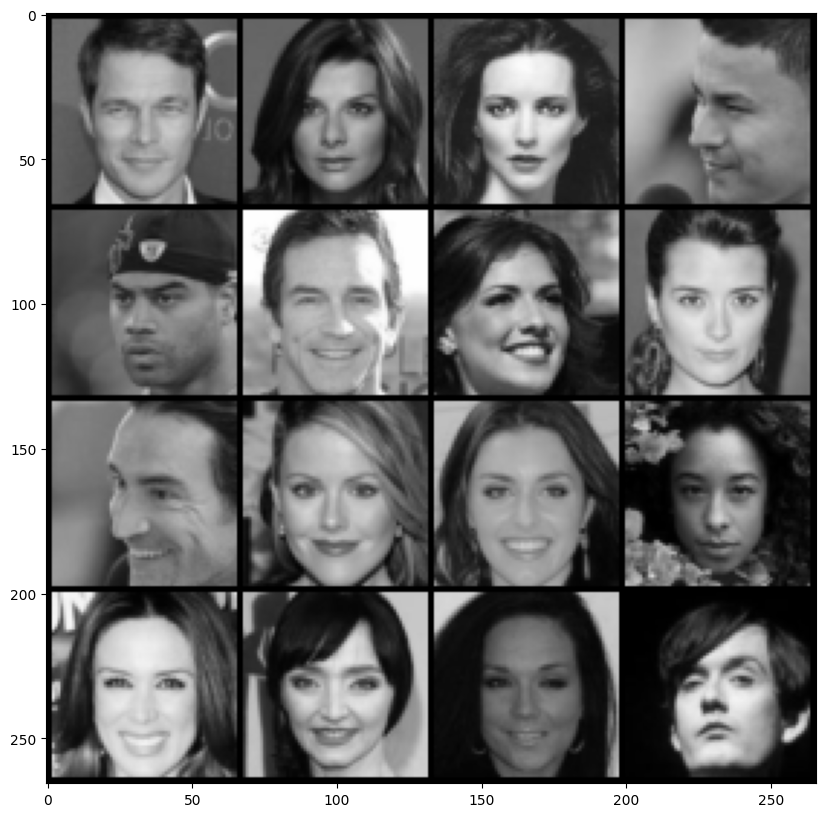

In [ ]:
# print some images
samples = torch.stack([train_dataset[i][0] for i in range(32, 48)], dim=0)

plt.figure(figsize=(10, 10))
plt.imshow(make_grid(samples, nrow=4).permute(1, 2, 0))
plt.show()

In [ ]:
BATCH_SIZE = 64

# you may find useful parameters `num_workers` and `pin_memory`
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(validation_dataset, batch_size=BATCH_SIZE)

# Autoencoder(4 points)

Why to use all this complicated formulaes and regularizations, what is the need for variational inference? To analyze the difference, let's first train just an autoencoder on the data:

In [ ]:
dimZ = 100  # Considering face reconstruction task, which size of representation seems reasonable?

# Define the decoder and encoder as networks with one hidden fc-layer
# (that means you will have 2 fc layers in each net)
# Use ReLU for hidden layers' activations
# GlorotUniform initialization for W
# Zero initialization for biases
# It's also convenient to put sigmoid activation on output layer to get nice normalized pics


class Autoencoder(nn.Module):

    def __init__(self, latent_dim):
        super(Autoencoder, self).__init__()
        # Encoder
        self.encoder = nn.Sequential(
            nn.Linear(64*64, 512),
            nn.ReLU(),
            nn.Linear(512, latent_dim)
        )
        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 512),
            nn.ReLU(),
            nn.Linear(512, 64*64),
            nn.Sigmoid()
        )

    def forward(self, x):
        x  = x.view(x.size(0), -1)
        latent_code = self.encoder(x)
        reconstruction = self.decoder(latent_code)
        reconstruction = reconstruction.view(reconstruction.size(0), 1, 64, 64)
        return reconstruction, latent_code

In [ ]:
from itertools import islice
def show_reconstruction(model, loader):
    images, _ = list(islice(loader, 1))[0]
    reconstruction, latent_code = model(images.to(device))

    reconstruction = reconstruction[:16].cpu()
    plt.imshow(make_grid(reconstruction, nrow=4).permute(1, 2, 0))

In [ ]:

# Create MSE loss function
criterion = torch.nn.MSELoss()

autoencoder = Autoencoder(dimZ).to(device)

# Use Adam optimizer
optimizer = optim.Adam(autoencoder.parameters(), lr=3e-4)

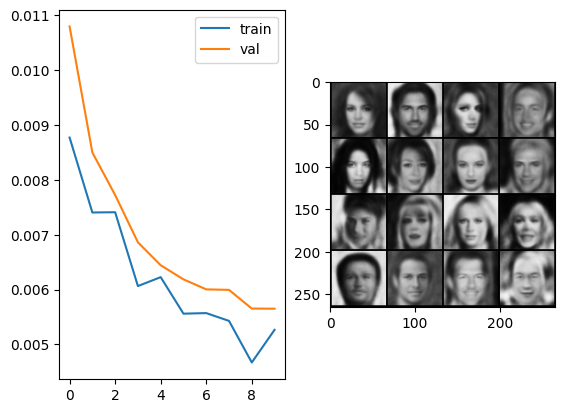

train_loss,█▆▆▃▄▃▃▂▁▂
val_loss,█▅▄▃▂▂▁▁▁▁
train_loss,0.00526
val_loss,0.00565


In [ ]:

# Train your autoencoder
# Visualize progress in reconstruction and loss decay
run = wandb.init(project="autoencoder")
config = run.config
config.learning_rate = 3e-4
config.batch_size = BATCH_SIZE

metrics = {
    "train_loss": [],
    "val_loss": [],
}
n_epoch = 10
tr_loss = 0
train_losses, val_losses = [], []

for epoch in range(n_epoch):
    autoencoder.train()
    for img, _ in train_loader:
        imh = img.to(device)
        optimizer.zero_grad()
        reconstruction, latent_code = autoencoder(imh)
        loss = criterion(reconstruction, imh)
        loss.backward()
        optimizer.step()
        tr_loss += loss.item()
    train_losses.append(loss.item())


    autoencoder.eval()
    val_loss = 0
    with torch.no_grad():
        for img, _ in val_loader:
            img = img.to(device)
            reconstruction, latent_code = autoencoder(img)
            loss = criterion(reconstruction, img)
            val_loss += loss.item()
    val_losses.append(loss.item())

    train_loss_epoch = train_losses[epoch]
    val_loss_epoch = val_losses[epoch]
    metrics["train_loss"].append((epoch + 1, train_loss_epoch))
    metrics["val_loss"].append((epoch + 1, val_loss_epoch))

    wandb.log({
        "train_loss": train_loss_epoch,
        "val_loss": val_loss_epoch,
    })

    display.clear_output(wait=True)
    plt.subplot(121)
    plt.plot(np.arange(len(train_losses)), train_losses, label='train')
    plt.plot(np.arange(len(val_losses)), val_losses, label='val')
    plt.legend()
    plt.subplot(122)
    show_reconstruction(autoencoder, val_loader)
    plt.show()

run.finish()

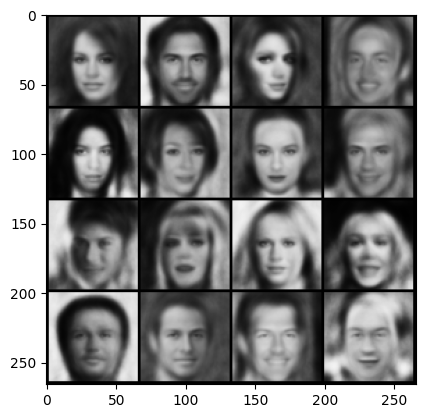

In [ ]:
# Examine the reconstructions
show_reconstruction(autoencoder, val_loader)

Reconstruction is not bad, right?

Yep

# Sampling

Let's now sample several latent vectors and perform inference from $z$, reconstruct an image given some random $z$ representations.

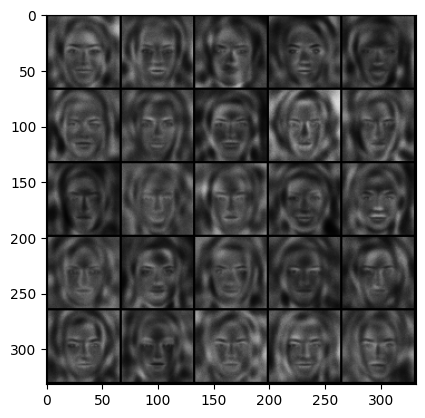

In [ ]:
z = torch.randn(25, dimZ) * 0.5
reconstruction = autoencoder.decoder(z.to(device)).clamp(0, 1)
reconstruction = reconstruction.view(25, 1, 64, 64)
plt.imshow(make_grid(reconstruction.cpu(), nrow=5).permute(1, 2, 0))
plt.show()


So, if we sample $z$ from normal, whould we eventually generate all possible faces? What do you think?

Of course, no. Generated `z` is highly likely to be close to central values(near to the null vector).

Moreover, a training sample is finite(so faces different from training sample wont be representet properly )))

# Variational Autoencoder(6 points)

Bayesian approach in deep learning considers everything in terms of distributions. Now our encoder generates not just a vector $z$ but posterior ditribution $q(z|x)$. In our case distribution $q$ is Gaussian distibution $N(\mu, \sigma)$ with parameters $\mu$, $\sigma$. Technically, the first difference is that you need to split bottleneck layer in two. One dense layer will generate vector $\mu$, and another will generate vector $\sigma$. Reparametrization trick should be implemented using the **gaussian_sampler** layer, that generates random vetor $\epsilon$ and returns $\mu+\sigma\epsilon \sim N(\mu, \sigma)$ .

Since our decoder is also a function that generates distribution, we need to do the same splitting for output layer. When testing the model we will look only on mean values, so one of the output will be actual autoencoder output.

In this homework we only ask for implementation of the simplest version of VAE - one $z$ sample per input. You can consider to sample several outputs from one input and average them.

In [ ]:
import torch.nn.functional as F
# to compare with conventional AE, keep these hyperparameters
# or change them for the values that you used before
dimZ = 100

# define the network
# you can start from https://github.com/pytorch/examples/blob/master/vae/main.py
# or Theano-based examples here https://github.com/Lasagne/Recipes/blob/master/examples/variational_autoencoder/variational_autoencoder.py
# and here https://github.com/y0ast/Variational-Autoencoder/blob/master/VAE.py
# but remember that this is not your ground truth since the data is not MNIST


class VAE(nn.Module):

    def __init__(self, latent_dim):
        super(VAE, self).__init__()
        self.dim = latent_dim

        self.encoder_fc1 = nn.Linear(64**2, 512)
        self.encoder_mu = nn.Linear(512, latent_dim)
        self.encoder_logsigma = nn.Linear(512, latent_dim)

        self.decoder_fc1 = nn.Linear(latent_dim, 512)
        self.decoder_fc2= nn.Linear(512, 64*64)

    def encode(self, x):
        h1 = F.relu(self.encoder_fc1(x))
        latent_mu = self.encoder_mu(h1)
        latent_logsigma = self.encoder_logsigma(h1)
        return latent_mu, latent_logsigma

    def decode(self, z):
        h3 = F.relu(self.decoder_fc1(z))
        return torch.sigmoid(self.decoder_fc2(h3)), torch.sigmoid(self.decoder_fc2(h3))

    def gaussian_sampler(self, mu, logsigma):
        noise = torch.randn_like(mu)
        return noise * logsigma.exp() + mu

    def forward(self, x):
        latent_mu, latent_logsigma = self.encode(x.view(-1, 64*64))
        z = self.gaussian_sampler(latent_mu, latent_logsigma)
        recon_mu, recon_logsigma = self.decode(z)
        return recon_mu, recon_logsigma, latent_mu, latent_logsigma

And the last, but not least! Place in the code where the most of the formulaes goes to - optimization objective. The objective for VAE has it's own name - variational lowerbound. And as for any lowerbound our intention is to maximize it. Here it is (for one sample $z$ per input $x$):

$$\mathcal{L} = -D_{KL}(q_{\phi}(z|x)||p(z)) + \log p_{\theta}(x|z) \to max$$

Your next task is to implement two functions that compute KL-divergence and the second term - log-likelihood of an output. Here is some necessary math for your convenience:

$$D_{KL} = -\frac{1}{2}\sum_{i=1}^{dimZ}(1+log(\sigma_i^2)-\mu_i^2-\sigma_i^2)$$
$$\log p_{\theta}(x|z) = \sum_{i=1}^{dimX}\log p_{\theta}(x_i|z)=\sum_{i=1}^{dimX} \log \Big( \frac{1}{\sigma_i\sqrt{2\pi}}e^{-\frac{(\mu_i-x)^2}{2\sigma_i^2}} \Big)=...$$

Don't forget in the code that you are using $\log\sigma$ as variable. Explain, why not $\sigma$?

In [ ]:
def KL_divergence(mu_z, logsigma_z):
    kl = -0.5 * torch.sum(1 + 2*logsigma_z - mu_z.pow(2) - torch.exp(logsigma_z).pow(2), dim=1)
    return kl.mean()

def log_likelihood(x, mu_gen, logsigma_gen):
    mu_gen = mu_gen
    logsigma_gen = logsigma_gen
    recon_loss = -0.5 * torch.sum(torch.log(2*torch.pi * torch.exp(logsigma_gen).pow(2)) +(mu_gen - x).pow(2) / (2*torch.exp(logsigma_gen).pow(2)), dim = 1)
    return recon_loss.mean()

def loss_vae(x, mu_gen, logsigma_gen, mu_z, logsigma_z):
    recon_loss = log_likelihood(x, mu_gen, logsigma_gen)
    kl_div = KL_divergence(mu_z, logsigma_z)
    total_loss = recon_loss - kl_div
    return total_loss

In [ ]:
from itertools import islice
def show_reconstruction_vae(model, loader):
    images, _ = list(islice(loader, 1))[0]
    mu_gen, _, _, _ = model(images.to(device))
    reconstruction = mu_gen[:16].cpu().clamp(0, 1)

    plt.imshow(make_grid(reconstruction, nrow=4).permute(1, 2, 0))

And train the model:

In [ ]:
criterion = loss_vae
vae = VAE(dimZ).to(device)
optimizer = optim.Adam(vae.parameters(), lr = 3e-4)

In [ ]:

# train your variational autoencoder
# visualize progress in reconstruction and loss decay
run = wandb.init(project="vae")
config = run.config
config.learning_rate = 3e-4
config.batch_size = BATCH_SIZE
config.dimZ = dimZ
n_epoch = 5
train_losses, val_losses = [], []

metrics = {
    "train_loss": [],
    "val_loss": [],
}

for epoch in range(n_epoch):
    vae.train()
    tr_loss = 0
    for img, _ in train_loader:
        img = img.to(device)
        optimizer.zero_grad()
        mu_gen, logsigma_gen, latent_mu, latent_logsigma = vae(img)
        loss = criterion(img, mu_gen, logsigma_gen, latent_mu, latent_logsigma)
        loss.backward()
        optimizer.step()
        tr_loss += loss.item()
    train_losses.append(loss.item())


    vae.eval()
    val_loss = 0
    with torch.no_grad():
        for img, _ in val_loader:
            img = img.to(device)
            mu_gen, logsigma_gen, latent_mu, latent_logsigma = vae(img.view(-1,1,64,64))
            loss = criterion(img, mu_gen, logsigma_gen, latent_mu, latent_logsigma)
            val_loss += loss.item()

    val_losses.append(loss.item())


    train_loss_epoch = train_losses[epoch]
    val_loss_epoсh = val_losses[epoch]
    metrics["train_loss"].append((epoch + 1, train_loss_epoch))
    metrics["val_loss"].append((epoch + 1,  val_loss_epoсh))

    wandb.log({
        "train_loss":  train_loss_epoch,
        "val_loss":  val_loss_epoсh,
    })

    display.clear_output(wait=True)
    plt.subplot(121)
    plt.plot(np.arange(len(train_losses)), train_losses, label='train')
    plt.plot(np.arange(len(val_losses)), val_losses, label='val')
    plt.legend()
    plt.subplot(122)
    show_reconstruction_vae(vae, val_loader)
    plt.show()
run.finish()

RuntimeError: shape '[64, 1, 64, 64]' is invalid for input of size 73728

In [ ]:
run.finish()

train_loss,█▁
val_loss,█▁
train_loss,-6.162697582596116e+20
val_loss,-5.000933260120927e+21


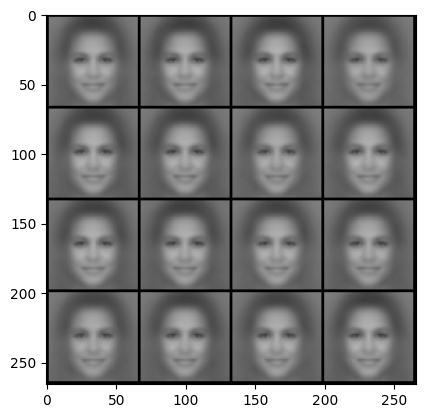

In [ ]:
show_reconstruction_vae(vae, val_loader)

And finally sample from VAE.

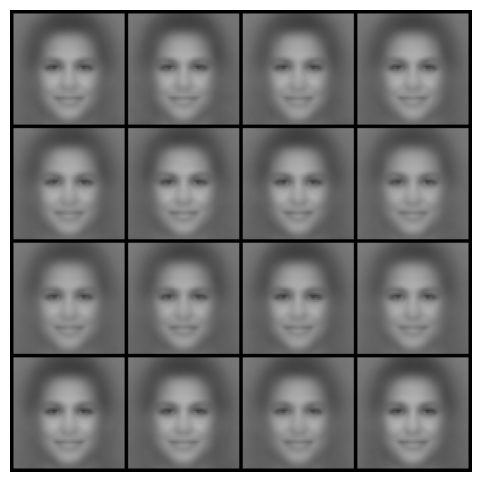

In [ ]:
def sample_from_vae(model, num_samples=16):
    model.eval()
    with torch.no_grad():
        z = torch.randn(num_samples, model.dim).to(device)
        generated_mu = model.mu_decoder(z).view(-1, 1, 64, 64).cpu().clamp(0, 1)

    plt.figure(figsize=(6, 6))
    plt.imshow(make_grid(generated_mu, nrow=4).permute(1, 2, 0))
    plt.axis("off")
    plt.show()

sample_from_vae(vae, num_samples=16)


:(

Even if in practice you do not see the much difference between AE and VAE, or VAE is even worse, the little bayesian inside you should be jumping for joy right now.

In VAE you can truly sample from image distribution $p(x)$, while in AE there is no easy and correct way to do it.